# Analyst Recommendation Anomaly

This notebook runs two monthly long-short strategies using the reusable modules in `src/`:

1. **Consensus:** long favorable (low) IBES mean recommendations and short unfavorable ones.
2. **Revision:** long upgrades and short downgrades.

> If WRDS files have not been downloaded, the notebook automatically uses clearly labeled synthetic data. Synthetic results demonstrate the code only and are not evidence of an anomaly.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.backtest import build_formation_panel, performance_summary, run_long_short_backtest
from src.config import BacktestConfig, OUTPUT_DIR, RAW_DIR, ensure_directories
from src.demo_data import make_demo_data
from src.signals import link_recommendations_to_crsp, make_recommendation_signals


## 1. Load data

Download licensed data first with:

```bash
python -m src.download_data --start 2000-01-01 --end 2025-12-31
```


In [2]:
required_files = {
    'recommendations': RAW_DIR / 'ibes_recommendations.parquet',
    'crsp': RAW_DIR / 'crsp_monthly.parquet',
    'names': RAW_DIR / 'crsp_names.parquet',
}

using_real_data = all(path.exists() for path in required_files.values())
if using_real_data:
    recommendations = pd.read_parquet(required_files['recommendations'])
    crsp = pd.read_parquet(required_files['crsp'])
    names = pd.read_parquet(required_files['names'])
    print('REAL WRDS DATA loaded')
else:
    recommendations, names, crsp = make_demo_data()
    print('SYNTHETIC DEMO DATA: results below are not empirical evidence')

print(f'IBES rows: {len(recommendations):,}')
print(f'CRSP rows: {len(crsp):,}')
recommendations.head()


REAL WRDS DATA loaded
IBES rows: 5,223,254
CRSP rows: 2,284,479


,ticker,cusip,oftic,statpers,meanrec,medrec,numrec
0,@0CL,AA619925,<NA>,2000-01-20,1.0,1.0,1.0
1,@0EI,EI180459,<NA>,2000-01-20,1.0,1.0,1.0
2,@0NI,FS665486,<NA>,2000-01-20,1.47,1.0,15.0
3,@0TL,AA617544,<NA>,2000-01-20,3.0,3.0,1.0
4,@11N,SF524943,<NA>,2000-01-20,3.0,3.0,3.0


## 2. Link identifiers and construct point-in-time signals

The link uses eight-character CUSIP plus CRSP's historical name-date interval. Ticker-only matching is avoided. A one-day lag means a recommendation snapshot dated on month-end cannot be traded at that same close.


In [3]:
linked = link_recommendations_to_crsp(recommendations, names)
signals = make_recommendation_signals(linked, publication_lag_days=1)

print(f'Link rate: {len(linked) / len(recommendations):.1%}')
signals[['permno', 'statpers', 'available_date', 'meanrec',
         'consensus_signal', 'revision_signal']].head()


/var/folders/nf/zfnfl40j2hb_zjsqj1rbjq140000gn/T/ipykernel_11470/2304398778.py:2: UserWarning: Dropping 88 ambiguous recommendation rows across 44 PERMNO/statpers pairs. Multiple IBES records map to the same security/date; revisions use the previous retained snapshot. Examples: [{'permno': 92893, 'statpers': Timestamp('2009-09-17 00:00:00')}, {'permno': 92893, 'statpers': Timestamp('2009-10-15 00:00:00')}, {'permno': 13639, 'statpers': Timestamp('2013-03-14 00:00:00')}, {'permno': 13191, 'statpers': Timestamp('2013-03-14 00:00:00')}, {'permno': 13639, 'statpers': Timestamp('2013-04-18 00:00:00')}]
  signals = make_recommendation_signals(linked, publication_lag_days=1)


Link rate: 25.0%


,permno,statpers,available_date,meanrec,consensus_signal,revision_signal
3717875,10001,2011-01-20,2011-01-21,1.0,-1.0,<NA>
3746827,10001,2011-02-17,2011-02-18,1.0,-1.0,0.0
3775840,10001,2011-03-17,2011-03-18,1.0,-1.0,0.0
3804820,10001,2011-04-14,2011-04-15,1.0,-1.0,0.0
3833815,10001,2011-05-19,2011-05-20,1.0,-1.0,0.0


## 3. Backtest the consensus strategy

At each month-end, the strategy uses only signals already available, forms equal-weighted top/bottom decile legs, and applies those weights to the next calendar month's CRSP return. Returns include CRSP delisting returns. Reported net returns subtract 10 basis points per unit of one-way turnover.


In [4]:
consensus_config = BacktestConfig(
    signal='consensus_signal',
    quantile=0.10,
    min_analysts=2,
    publication_lag_days=1,
    transaction_cost_bps=10.0,
)
consensus_panel = build_formation_panel(crsp, signals, consensus_config)
consensus_results, consensus_holdings = run_long_short_backtest(
    consensus_panel, consensus_config
)
performance_summary(consensus_results).to_frame('consensus')


/Users/apple/Desktop/pandas_pytorch_practice/analyst_recommendation_anomaly/src/signals.py:136: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(pieces, ignore_index=True)
/Users/apple/Desktop/pandas_pytorch_practice/analyst_recommendation_anomaly/src/signals.py:136: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(pieces, ignore_index=True)
/Users/apple/Desktop/pandas_pytorch_practice/analyst_recommendation_anomaly/src/signals.py:136: FutureWarning: The behavior of D

,consensus
months,172.000000
total_months,300.000000
missing_return_months,128.000000
months_with_missing_held_return,128.000000
return_coverage,0.573333
cagr,NaN
annualized_mean_return,0.001340
annual_volatility,0.123241
sharpe_zero_rf,0.010872
max_drawdown,NaN


## 4. Backtest the revision strategy

`revision_signal = previous_meanrec - current_meanrec`, so positive values are upgrades. The first observation for each security is missing by construction.


In [5]:
revision_config = BacktestConfig(
    signal='revision_signal',
    quantile=0.10,
    min_analysts=2,
    publication_lag_days=1,
    transaction_cost_bps=10.0,
)
revision_panel = build_formation_panel(crsp, signals, revision_config)
revision_results, revision_holdings = run_long_short_backtest(
    revision_panel, revision_config
)
summaries = pd.concat(
    [performance_summary(consensus_results).rename('consensus'),
     performance_summary(revision_results).rename('revision')],
    axis=1,
)
summaries


/Users/apple/Desktop/pandas_pytorch_practice/analyst_recommendation_anomaly/src/signals.py:136: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(pieces, ignore_index=True)
/Users/apple/Desktop/pandas_pytorch_practice/analyst_recommendation_anomaly/src/signals.py:136: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  return pd.concat(pieces, ignore_index=True)
/Users/apple/Desktop/pandas_pytorch_practice/analyst_recommendation_anomaly/src/signals.py:136: FutureWarning: The behavior of D

,consensus,revision
months,172.000000,217.000000
total_months,300.000000,300.000000
missing_return_months,128.000000,83.000000
months_with_missing_held_return,128.000000,83.000000
return_coverage,0.573333,0.723333
cagr,NaN,NaN
annualized_mean_return,0.001340,-0.011242
annual_volatility,0.123241,0.060482
sharpe_zero_rf,0.010872,-0.185865
max_drawdown,NaN,NaN


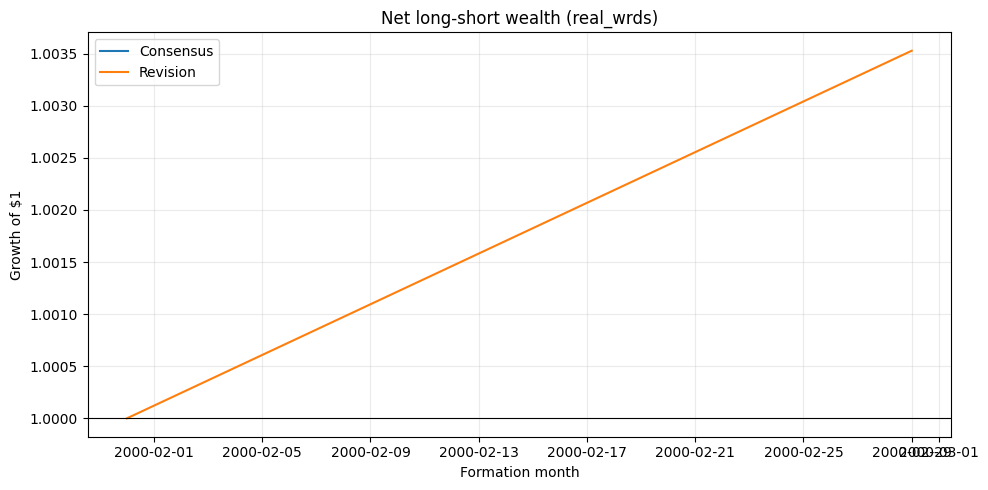

In [6]:
ensure_directories()
data_source = 'real_wrds' if using_real_data else 'synthetic_demo'
consensus_results['data_source'] = data_source
revision_results['data_source'] = data_source
consensus_results.to_csv(OUTPUT_DIR / 'consensus_monthly_results.csv', index=False)
revision_results.to_csv(OUTPUT_DIR / 'revision_monthly_results.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(consensus_results['date'], consensus_results['wealth'], label='Consensus')
ax.plot(revision_results['date'], revision_results['wealth'], label='Revision')
ax.axhline(1.0, color='black', linewidth=0.8)
ax.set(title=f'Net long-short wealth ({data_source})', xlabel='Formation month', ylabel='Growth of $1')
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'strategy_wealth.png', dpi=150)
plt.show()


## 5. Leakage and data-quality audit

The assertions below are intended to fail loudly if timing or portfolio construction becomes unsafe. Outcome coverage below 100% is not filled with zero; any missing return on an actually held stock makes that month's portfolio return missing.


In [7]:
assert (consensus_panel['available_date'] <= consensus_panel['date']).all()
assert (consensus_panel['return_month'] == consensus_panel['formation_month'] + 1).all()
assert not consensus_panel.duplicated(['permno', 'date']).any()
assert (consensus_holdings.groupby('date')['weight'].sum().abs() < 1e-10).all()

audit = pd.Series({
    'using_real_wrds_data': using_real_data,
    'ibes_to_crsp_link_rate': len(linked) / len(recommendations),
    'minimum_outcome_coverage': consensus_results['outcome_coverage'].min(),
    'months_with_missing_held_return': int(consensus_results['held_return_missing'].sum()),
    'average_number_of_positions': consensus_results['n_securities'].mean(),
})
audit


using_real_wrds_data                  True
ibes_to_crsp_link_rate             0.24968
minimum_outcome_coverage               0.0
months_with_missing_held_return        128
average_number_of_positions         496.64
dtype: object

## 6. Interpretation checklist

Before treating real-data results as evidence, check all of the following:

- The notebook says **REAL WRDS DATA**, not synthetic demo data.
- The IBES-to-CRSP link rate and ambiguous/unmatched observations were investigated.
- Delisting-return coverage is reasonable and no missing held-stock returns were silently set to zero.
- Results survive sensible price, size, liquidity, weighting, lag, and transaction-cost choices.
- Statistical inference accounts for time-series dependence, and returns are tested against standard factors.
- No current constituent list, current ticker map, or revised future information entered the historical universe.
- Strategy definitions were chosen before examining performance, or multiple-testing corrections are reported.
